# Dynamic Neural Network Model

The feedforward model in the previous notebook predicted the motor's current and speed at individual time steps.

This notebook extends the model to include the motor's behaviour over time. Recurrent neural networks are used to predict the current and speed at the next time step based on the motor's current state and the information carried through the sequence.

Three recurrent models are tested: a Simple RNN, LSTM, and GRU.

In [36]:
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
%matplotlib inline

## Preparing the Data

The fixed-time dataset is used so that each consecutive sample represents the same time interval.

Each simulation run contains the motor response from the start of the simulation to 0.2 seconds. The applied torque is also corrected in the dataset to reflect when the load is actually applied at 0.1 seconds.

In [37]:
dataset = pd.read_csv('../data/motor_dataset_fixed_time.csv')
dataset.head()

,Voltage,Load Torque,Time,Current,Speed
0,0.1,0.0,0.000,1.000000e-10,0.000000
1,0.1,0.0,0.001,2.564020e-02,0.043862
2,0.1,0.0,0.002,2.564018e-02,0.043910
3,0.1,0.0,0.003,2.564025e-02,0.044448
4,0.1,0.0,0.004,2.564019e-02,0.043912


In [38]:
print(dataset.shape)

(33165, 5)


In [39]:
# Identify individual simulation runs.
# Time resets to zero whenever a new Simulink simulation begins.
dataset['Run'] = (dataset['Time'].diff()<0).cumsum()
dataset.head()

,Voltage,Load Torque,Time,Current,Speed,Run
0,0.1,0.0,0.000,1.000000e-10,0.000000,0
1,0.1,0.0,0.001,2.564020e-02,0.043862,0
2,0.1,0.0,0.002,2.564018e-02,0.043910,0
3,0.1,0.0,0.003,2.564025e-02,0.044448,0
4,0.1,0.0,0.004,2.564019e-02,0.043912,0


In [40]:
dataset['Applied Torque'] = np.where(dataset['Time'] < 0.1, 0,dataset['Load Torque'])

## Creating the Sequences

The recurrent models need the data in the form of sequences.

For each simulation run, the voltage, applied torque, current, and speed at one time step are used to predict the current and speed at the following time step.

The last input time step is therefore matched with the last available target time step, giving 200 input-target transitions for each run.

In [41]:
# Define the features used by the model and the outputs it will predict
input_features = ['Voltage', 'Applied Torque', 'Current', 'Speed']
output_features = ['Current', 'Speed']

x = []
y = []

for run_id, run_data in dataset.groupby('Run'):
    run_data = run_data.sort_values('Time')
    current_inputs = run_data[input_features].iloc[:-1].values
    next_outputs = run_data[output_features].iloc[1:].values

    x.append(current_inputs)
    y.append(next_outputs)

In [42]:
x = np.array(x)
y = np.array(y)

## Train-Test Split and Scaling

The simulation runs are split into training and test sets rather than splitting individual time steps.

This keeps each complete motor trajectory together and prevents different parts of the same run from appearing in both sets.

The input and output values are then scaled before training.

In [43]:
run_ids = np.arange(len(x))

train_ids, test_ids = train_test_split(run_ids, test_size=0.2,random_state=42)

X_train = x[train_ids]
y_train = y[train_ids]

X_test = x[test_ids]
y_test = y[test_ids]

In [44]:
input_scaler = StandardScaler()
output_scaler = StandardScaler()

X_train_scaled = input_scaler.fit_transform(X_train.reshape(-1, X_train.shape[-1])).reshape(X_train.shape)
X_test_scaled = input_scaler.transform(X_test.reshape(-1, X_test.shape[-1])).reshape(X_test.shape)

y_train_scaled = output_scaler.fit_transform(y_train.reshape(-1, y_train.shape[-1])).reshape(y_train.shape)
y_test_scaled = output_scaler.transform(y_test.reshape(-1, y_test.shape[-1])).reshape(y_test.shape)

## Simple RNN

A Simple RNN is used first as the basic recurrent model.

The RNN processes the motor data as a sequence and carries information from previous time steps while predicting the current and speed at each next time step.

In [45]:
model = keras.Sequential([keras.Input(shape=(200,4)),
                          layers.SimpleRNN(32, return_sequences=True),
                          layers.Dense(2)])

In [46]:
model.compile(optimizer = 'adam', loss = 'mse', metrics = ['mae'])

In [47]:
# Note: validation_split reserves the last 20% of training sequences for validation.
# The sequences are not shuffled before this validation subset is selected.
history = model.fit(X_train_scaled, y_train_scaled, validation_split = 0.2, epochs = 100, batch_size = 16, verbose = 1)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 9s 743ms/step - loss: 0.3300 - mae: 0.4452 - val_loss: 0.2621 - val_mae: 0.3500
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 90ms/step - loss: 0.1556 - mae: 0.2687 - val_loss: 0.1721 - val_mae: 0.2544
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step - loss: 0.1113 - mae: 0.2190 - val_loss: 0.1434 - val_mae: 0.2433
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 97ms/step - loss: 0.0962 - mae: 0.2113 - val_loss: 0.1193 - val_mae: 0.2124
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step - loss: 0.0763 - mae: 0.1724 - val_loss: 0.0980 - val_mae: 0.1699
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 100ms/step - loss: 0.0634 - mae: 0.1443 - val_loss: 0.0858 - val_mae: 0.1529
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 74ms/step - loss: 0.0554 - mae: 0.1301 - val_loss: 0.0749 - val_mae: 0.1333
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - loss: 0.0482 - mae: 0.1135 - val_loss: 0.0666 - val_mae: 0.1238
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step - loss: 0.0435 - mae

In [48]:
y_pred_scaled = model.predict(X_test_scaled)
y_pred = output_scaler.inverse_transform(y_pred_scaled.reshape(-1,2)).reshape(y_pred_scaled.shape)
y_test_original = output_scaler.inverse_transform(y_test_scaled.reshape(-1,2)).reshape(y_test_scaled.shape)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 548ms/step


In [49]:
# Calculate prediction errors for current and speed
current_mae = mean_absolute_error(y_test_original[:, :, 0], y_pred[:, :, 0])
speed_mae = mean_absolute_error(y_test_original[:, :, 1], y_pred[:, :, 1])

current_rmse = np.sqrt(mean_squared_error(y_test_original[:, :, 0], y_pred[:, :, 0]))
speed_rmse = np.sqrt(mean_squared_error(y_test_original[:, :, 1], y_pred[:, :, 1]))

print(f'Current MAE: {current_mae}')
print(f'Current RMSE: {current_rmse}')

print(f'Speed MAE: {speed_mae}')
print(f'Speed RMSE: {speed_rmse}')

Current MAE: 0.001358515613782911
Current RMSE: 0.003921313006492862
Speed MAE: 127.23747282822136
Speed RMSE: 203.05672590113048


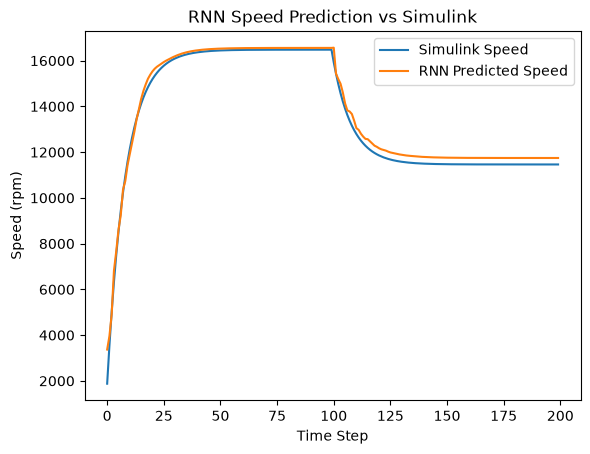

In [50]:
# Compare predicted speed with the speed produced by Simulink
run = 0
plt.plot(y_test_original[run, :, 1], label = 'Simulink Speed')
plt.plot(y_pred[run, :, 1], label = 'RNN Predicted Speed')
plt.xlabel('Time Step')
plt.ylabel('Speed (rpm)')
plt.title('RNN Speed Prediction vs Simulink')
plt.legend()

## LSTM

An LSTM is tested using the same input data and training setup as the RNN.

LSTM uses additional gates to control the information carried through the sequence, allowing it to retain useful information from earlier time steps.

In [51]:
lstm_model = keras.Sequential([keras.Input(shape=(200,4)),
                          layers.LSTM(32, return_sequences=True),
                          layers.Dense(2)])

lstm_model.compile(optimizer = 'adam', loss = 'mse', metrics = ['mae'])

lstm_history = lstm_model.fit(X_train_scaled, y_train_scaled, validation_split = 0.2, epochs = 100, batch_size = 16, verbose = 1)

y_pred_scaled = lstm_model.predict(X_test_scaled)
y_pred = output_scaler.inverse_transform(y_pred_scaled.reshape(-1,2)).reshape(y_pred_scaled.shape)
y_test_original = output_scaler.inverse_transform(y_test_scaled.reshape(-1,2)).reshape(y_test_scaled.shape)


Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 10s 897ms/step - loss: 1.0104 - mae: 0.7852 - val_loss: 0.8911 - val_mae: 0.6976
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 122ms/step - loss: 0.6504 - mae: 0.6060 - val_loss: 0.5818 - val_mae: 0.5354
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 114ms/step - loss: 0.4028 - mae: 0.4523 - val_loss: 0.3644 - val_mae: 0.3979
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 123ms/step - loss: 0.2382 - mae: 0.3291 - val_loss: 0.2260 - val_mae: 0.2959
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 138ms/step - loss: 0.1425 - mae: 0.2430 - val_loss: 0.1526 - val_mae: 0.2373
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 133ms/step - loss: 0.0988 - mae: 0.2021 - val_loss: 0.1200 - val_mae: 0.2160
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step - loss: 0.0821 - mae: 0.1903 - val_loss: 0.1018 - val_mae: 0.2037
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 117ms/step - loss: 0.0722 - mae: 0.1798 - val_loss: 0.0871 - val_mae: 0.1860
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 107ms/step - loss: 0.06

In [52]:
# Calculate prediction errors for current and speed
current_mae = mean_absolute_error(y_test_original[:, :, 0], y_pred[:, :, 0])
speed_mae = mean_absolute_error(y_test_original[:, :, 1], y_pred[:, :, 1])

current_rmse = np.sqrt(mean_squared_error(y_test_original[:, :, 0], y_pred[:, :, 0]))
speed_rmse = np.sqrt(mean_squared_error(y_test_original[:, :, 1], y_pred[:, :, 1]))

print(f'LSTM Current MAE: {current_mae}')
print(f'LSTM Current RMSE: {current_rmse}')

print(f'LSTM Speed MAE: {speed_mae}')
print(f'LSTM Speed RMSE: {speed_rmse}')

LSTM Current MAE: 0.002219837546784507
LSTM Current RMSE: 0.01053906448007225
LSTM Speed MAE: 135.11525303371184
LSTM Speed RMSE: 395.06715151380405


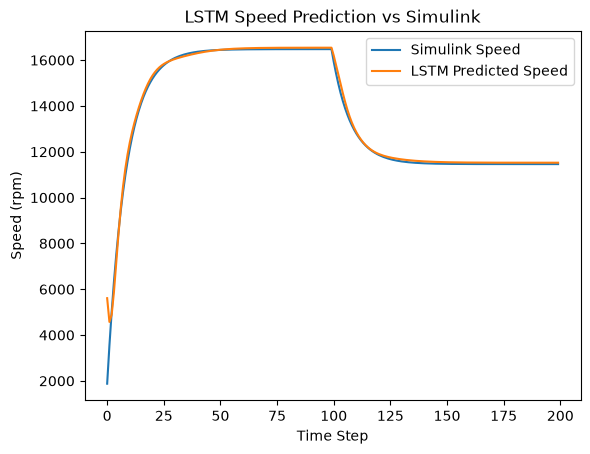

In [53]:
# Compare predicted speed with the speed produced by Simulink
run = 0
plt.plot(y_test_original[run, :, 1], label = 'Simulink Speed')
plt.plot(y_pred[run, :, 1], label = 'LSTM Predicted Speed')
plt.xlabel('Time Step')
plt.ylabel('Speed (rpm)')
plt.title('LSTM Speed Prediction vs Simulink')
plt.legend()

## GRU

A GRU is tested using the same setup as the RNN and LSTM.

The GRU also uses gates to control the information passed through the sequence, but uses a simpler structure than the LSTM.

In [54]:
gru_model = keras.Sequential([keras.Input(shape=(200,4)),
                          layers.GRU(32, return_sequences=True),
                          layers.Dense(2)])

gru_model.compile(optimizer = 'adam', loss = 'mse', metrics = ['mae'])

gru_history = gru_model.fit(X_train_scaled, y_train_scaled, validation_split = 0.2, epochs = 100, batch_size = 16, verbose = 1)

y_pred_scaled = gru_model.predict(X_test_scaled)
y_pred = output_scaler.inverse_transform(y_pred_scaled.reshape(-1,2)).reshape(y_pred_scaled.shape)
y_test_original = output_scaler.inverse_transform(y_test_scaled.reshape(-1,2)).reshape(y_test_scaled.shape)

# Calculate prediction errors for current and speed
current_mae = mean_absolute_error(y_test_original[:, :, 0], y_pred[:, :, 0])
speed_mae = mean_absolute_error(y_test_original[:, :, 1], y_pred[:, :, 1])

current_rmse = np.sqrt(mean_squared_error(y_test_original[:, :, 0], y_pred[:, :, 0]))
speed_rmse = np.sqrt(mean_squared_error(y_test_original[:, :, 1], y_pred[:, :, 1]))

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 7s 713ms/step - loss: 0.8522 - mae: 0.7537 - val_loss: 0.8128 - val_mae: 0.7020
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 124ms/step - loss: 0.5687 - mae: 0.6085 - val_loss: 0.5289 - val_mae: 0.5569
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 129ms/step - loss: 0.3486 - mae: 0.4688 - val_loss: 0.3114 - val_mae: 0.4138
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 128ms/step - loss: 0.1884 - mae: 0.3325 - val_loss: 0.1623 - val_mae: 0.2754
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step - loss: 0.0878 - mae: 0.2037 - val_loss: 0.0794 - val_mae: 0.1521
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 124ms/step - loss: 0.0414 - mae: 0.1039 - val_loss: 0.0498 - val_mae: 0.1046
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 125ms/step - loss: 0.0318 - mae: 0.0913 - val_loss: 0.0466 - val_mae: 0.1179
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 143ms/step - loss: 0.0340 - mae: 0.1085 - val_loss: 0.0459 - val_mae: 0.1229
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 128ms/step - loss: 0.033

In [55]:
print(f'GRU Current MAE: {current_mae}')
print(f'GRU Current RMSE: {current_rmse}')

print(f'GRU Speed MAE: {speed_mae}')
print(f'GRU Speed RMSE: {speed_rmse}')

GRU Current MAE: 0.0020023655334943683
GRU Current RMSE: 0.006356320471260132
GRU Speed MAE: 137.9034465633395
GRU Speed RMSE: 225.3762944940528


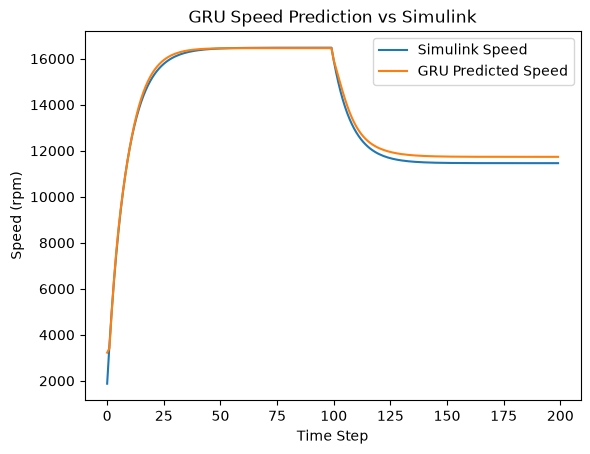

In [56]:
# Compare predicted speed with the speed produced by Simulink
run = 0
plt.plot(y_test_original[run, :, 1], label = 'Simulink Speed')
plt.plot(y_pred[run, :, 1], label = 'GRU Predicted Speed')
plt.xlabel('Time Step')
plt.ylabel('Speed (rpm)')
plt.title('GRU Speed Prediction vs Simulink')
plt.legend()

## Multi-Step Rollout

The models above are evaluated by predicting the next state while the true sequence is still provided as input.

A multi-step rollout tests the models differently. After the first prediction, the predicted current and speed are fed back into the model for the next step. The process continues for the rest of the simulation.

This allows the models to be tested on their ability to reproduce the motor's behaviour over an entire trajectory rather than only making individual next-step predictions.

In [57]:
# Persistence baseline: predict that current and speed remain unchanged
persistence_speed_mae = np.abs(X_test[:, :, 3] - y_test[:, :, 1]).mean()
persistence_current_mae = np.abs(X_test[:, :, 2] - y_test[:, :, 0]).mean()

print('Persistence Speed MAE:', persistence_speed_mae)
print('Persistence Current MAE:', persistence_current_mae)

Persistence Speed MAE: 71.23526663607352
Persistence Current MAE: 0.0021347858628005733


## Maintaining the Recurrent State

The one-step persistence baseline provides a simple reference by using the current state as the next state.

The recurrent models can perform well on one-step predictions because the true state is provided at every time step. A more demanding test is to let the models use their own predictions during a rollout.

The first rollout implementation did not maintain the recurrent state between prediction steps. A stateful version of each model is therefore created for the rollout. The trained weights are copied into these models so that the rollout uses the models that have already been trained.

In [58]:
def make_step_model(cell):
    m = keras.Sequential([
        keras.Input(batch_shape=(1, 1, 4)),
        cell(32, return_sequences=True, stateful=True),
        layers.Dense(2)])
    return m

def rollout(step_model, x_scaled_run, input_scaler, output_scaler):
    for layer in step_model.layers:
        if hasattr(layer, 'reset_state'):
            layer.reset_state()

    inp = x_scaled_run.copy()
    predictions = []

    for t in range(len(inp)):
        prediction = step_model(inp[t].reshape(1, 1, 4), training=False).numpy()[0, 0]
        predictions.append(prediction)
        if t < len(inp) - 1:
            # Convert predicted current and speed to their original units
            prediction_original = output_scaler.inverse_transform(prediction.reshape(1, 2))[0]
            # Recover the next input row in its original units
            next_input_original = input_scaler.inverse_transform(inp[t + 1].reshape(1, 4))[0]
            # Replace current and speed with the predictions
            next_input_original[2:] = prediction_original
            # Scale the complete row using the input scaler
            inp[t + 1] = input_scaler.transform(next_input_original.reshape(1, 4))[0]
    return np.array(predictions)

In [59]:
run = 0

step_rnn = make_step_model(layers.SimpleRNN)
step_rnn.set_weights(model.get_weights())

step_lstm = make_step_model(layers.LSTM)
step_lstm.set_weights(lstm_model.get_weights())

step_gru = make_step_model(layers.GRU)
step_gru.set_weights(gru_model.get_weights())

rnn_rollout = rollout(step_rnn, X_test_scaled[run], input_scaler, output_scaler)
lstm_rollout = rollout(step_lstm, X_test_scaled[run], input_scaler, output_scaler)
gru_rollout = rollout(step_gru, X_test_scaled[run], input_scaler, output_scaler)

In [60]:
rnn_rollout_original = output_scaler.inverse_transform(rnn_rollout)
lstm_rollout_original = output_scaler.inverse_transform(lstm_rollout)
gru_rollout_original = output_scaler.inverse_transform(gru_rollout)

actual_run = y_test_original[run]

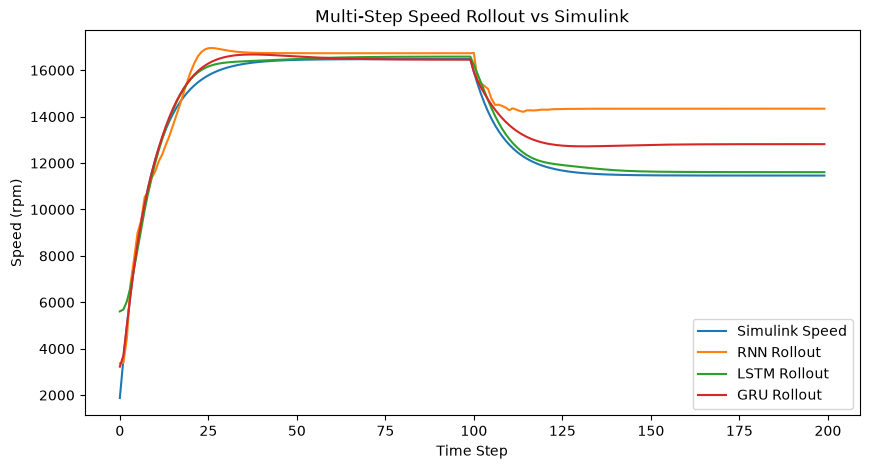

In [61]:
plt.figure(figsize=(10, 5))

plt.plot(actual_run[:, 1], label='Simulink Speed')
plt.plot(rnn_rollout_original[:, 1], label='RNN Rollout')
plt.plot(lstm_rollout_original[:, 1], label='LSTM Rollout')
plt.plot(gru_rollout_original[:, 1], label='GRU Rollout')

plt.xlabel('Time Step')
plt.ylabel('Speed (rpm)')
plt.title('Multi-Step Speed Rollout vs Simulink')
plt.legend()
plt.show()

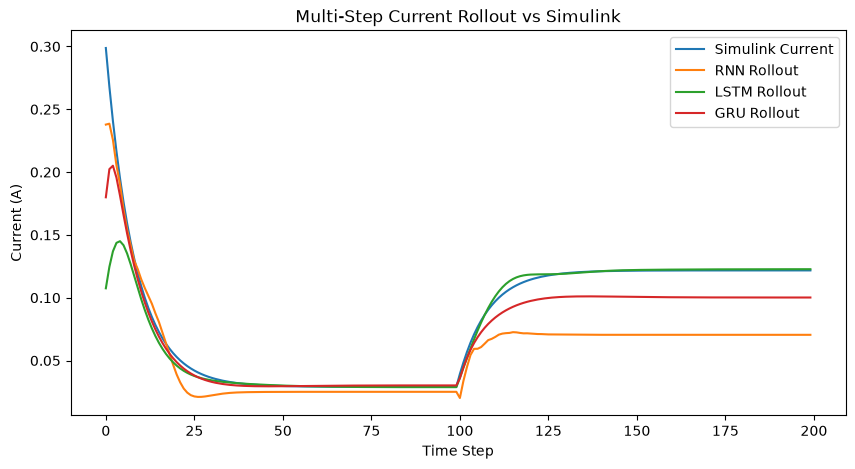

In [62]:
plt.figure(figsize=(10, 5))

plt.plot(actual_run[:, 0], label='Simulink Current')
plt.plot(rnn_rollout_original[:, 0], label='RNN Rollout')
plt.plot(lstm_rollout_original[:, 0], label='LSTM Rollout')
plt.plot(gru_rollout_original[:, 0], label='GRU Rollout')

plt.xlabel('Time Step')
plt.ylabel('Current (A)')
plt.title('Multi-Step Current Rollout vs Simulink')
plt.legend()
plt.show()

In [63]:
rnn_speed_mae = mean_absolute_error(actual_run[:, 1],rnn_rollout_original[:, 1])
lstm_speed_mae = mean_absolute_error(actual_run[:, 1],lstm_rollout_original[:, 1])
gru_speed_mae = mean_absolute_error(actual_run[:, 1],gru_rollout_original[:, 1])

print('RNN Speed Rollout MAE:', rnn_speed_mae)
print('LSTM Speed Rollout MAE:', lstm_speed_mae)
print('GRU Speed Rollout MAE:', gru_speed_mae)

RNN Speed Rollout MAE: 1482.1600004657996
LSTM Speed Rollout MAE: 198.9499691103317
GRU Speed Rollout MAE: 667.7365039066833


In [64]:
rnn_current_mae = mean_absolute_error(actual_run[:, 0],rnn_rollout_original[:, 0])
lstm_current_mae = mean_absolute_error(actual_run[:, 0],lstm_rollout_original[:, 0])
gru_current_mae = mean_absolute_error(actual_run[:, 0],gru_rollout_original[:, 0])

print('RNN Current Rollout MAE:', rnn_current_mae)
print('LSTM Current Rollout MAE:', lstm_current_mae)
print('GRU Current Rollout MAE:', gru_current_mae)

RNN Current Rollout MAE: 0.02655362468125506
LSTM Current Rollout MAE: 0.00483783086900889
GRU Current Rollout MAE: 0.011586680535238649


## Evaluating the Rollouts

A single test run can show how the models behave during a rollout, but it does not give a complete view of their performance.

The rollout is therefore repeated across all test runs. The mean absolute error for current and speed is calculated for each run and then used to compare the models across the test set.

In [65]:
rollout_results = []

for run in range(len(X_test_scaled)):
    actual_run = y_test_original[run]

    rnn_prediction = rollout(step_rnn, X_test_scaled[run], input_scaler, output_scaler)
    lstm_prediction = rollout(step_lstm, X_test_scaled[run], input_scaler, output_scaler)
    gru_prediction = rollout(step_gru, X_test_scaled[run], input_scaler, output_scaler)

    rnn_prediction = output_scaler.inverse_transform(rnn_prediction)
    lstm_prediction = output_scaler.inverse_transform(lstm_prediction)
    gru_prediction = output_scaler.inverse_transform(gru_prediction)

    rollout_results.append({'RNN Current MAE': mean_absolute_error(actual_run[:, 0],rnn_prediction[:, 0]),
                            'RNN Speed MAE': mean_absolute_error(actual_run[:, 1],rnn_prediction[:, 1]),
                            'LSTM Current MAE': mean_absolute_error(actual_run[:, 0],lstm_prediction[:, 0]),
                            'LSTM Speed MAE': mean_absolute_error(actual_run[:, 1],lstm_prediction[:, 1]),
                            'GRU Current MAE': mean_absolute_error(actual_run[:, 0],gru_prediction[:, 0]),
                            'GRU Speed MAE': mean_absolute_error(actual_run[:, 1],gru_prediction[:, 1])})

rollout_results = pd.DataFrame(rollout_results)
rollout_results

,RNN Current MAE,RNN Speed MAE,LSTM Current MAE,LSTM Speed MAE,GRU Current MAE,GRU Speed MAE
0,0.026554,1482.160000,0.004838,198.949969,0.011587,667.736504
1,0.011224,654.555581,0.004716,177.112262,0.004798,541.114738
2,0.015282,911.561963,0.006764,167.337323,0.006725,580.714264
3,0.055561,2588.186858,0.001314,118.791821,0.007321,632.745800
4,0.034432,1748.234374,0.004173,207.751815,0.004793,256.824854
5,0.043226,2080.003172,0.005502,319.484642,0.003829,217.003873
6,0.030403,1724.785055,0.006384,296.665583,0.006404,773.410047
7,0.045550,2064.798545,0.003489,217.701244,0.004734,556.166847
8,0.031067,1905.885216,0.003386,124.176870,0.009457,750.519060
9,0.021182,1101.108225,0.005893,288.087200,0.012030,561.957579


In [66]:
print('Average Rollout MAE Across Test Runs')

print('RNN Current:', rollout_results['RNN Current MAE'].mean())
print('RNN Speed:', rollout_results['RNN Speed MAE'].mean())
print('LSTM Current:', rollout_results['LSTM Current MAE'].mean())
print('LSTM Speed:', rollout_results['LSTM Speed MAE'].mean())
print('GRU Current:', rollout_results['GRU Current MAE'].mean())
print('GRU Speed:', rollout_results['GRU Speed MAE'].mean())

Average Rollout MAE Across Test Runs
RNN Current: 0.03253221248540485
RNN Speed: 1626.3844751567187
LSTM Current: 0.004230720122233988
LSTM Speed: 228.4223313002427
GRU Current: 0.006375212053787165
GRU Speed: 481.94126725695946


## Dynamic Model Comparison

The following plot compares the multi-step speed predictions from all three recurrent models against the Simulink trajectory for one test run.

The rollout metrics calculated above provide the broader comparison across all test runs.

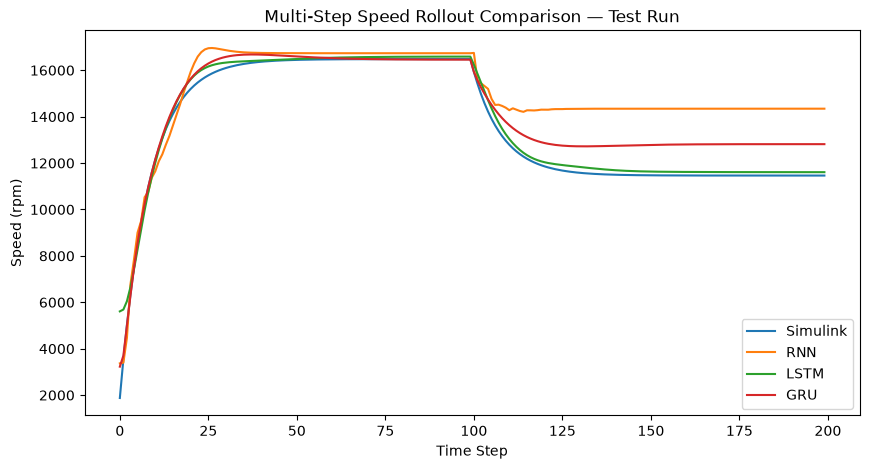

In [67]:
run = 0

actual_run = y_test_original[run]
rnn_prediction = output_scaler.inverse_transform(rollout(step_rnn, X_test_scaled[run], input_scaler, output_scaler))
lstm_prediction = output_scaler.inverse_transform(rollout(step_lstm, X_test_scaled[run], input_scaler, output_scaler))
gru_prediction = output_scaler.inverse_transform(rollout(step_gru, X_test_scaled[run], input_scaler, output_scaler))

plt.figure(figsize=(10, 5))
plt.plot(actual_run[:, 1], label='Simulink')
plt.plot(rnn_prediction[:, 1], label='RNN')
plt.plot(lstm_prediction[:, 1], label='LSTM')
plt.plot(gru_prediction[:, 1], label='GRU')

plt.xlabel('Time Step')
plt.ylabel('Speed (rpm)')
plt.title('Multi-Step Speed Rollout Comparison — Test Run')
plt.legend()
plt.show()

In [68]:
model.save('../models/rnn_model.keras')
lstm_model.save('../models/lstm_model.keras')
gru_model.save('../models/gru_model.keras')

In [69]:
joblib.dump(input_scaler, '../models/input_scaler.pkl')
joblib.dump(output_scaler, '../models/output_scaler.pkl')

['../models/output_scaler.pkl']

## Results & Next Step

This notebook trains Simple RNN, LSTM, and GRU models to predict the next current and speed values from simulated motor sequences.

One-step prediction evaluates the models while the true input sequence is available. Multi-step rollout evaluates how their predictions develop when predicted current and speed are fed back into subsequent steps.

**Next:** assess how closely the learned dynamic models reproduce the simulated motor's transient and steady-state behaviour.